# 06 - Why does compressed depth score better? A coverage-bias test

Notebook 05 found that on KITTI the shadow IoU is highest for the most *compressed* depth
(shape gamma 0.6, focal 0.6), not at the truth. We guessed a coverage bias: compressed depth
casts longer shadows, and IoU against a detector that marks a sizeable part of the road
rewards a larger predicted mask even when it is in the wrong place. The study CSV did not
store the rendered shadow area, so here we measure it.

Two checks:
1. On KITTI (drive 0001, DA-V2-S, the threshold detector, CPU), does the rendered shadow
   area grow as depth is compressed, and does the IoU follow the area?
2. Does a chance-corrected score (Cohen's kappa, `scene.kappa`) remove the bias? On the
   synthetic street, where the truth is exact, kappa must still peak at the truth; on KITTI
   it must no longer prefer the wrong value.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import kitti
import scene
import shadows
import sun
import synthetic

DATE_DIR = ROOT / "data/raw/2011_09_26"
DRIVE = DATE_DIR / "2011_09_26_drive_0001_sync"
FIG = ROOT / "outputs/figures"
OUT = ROOT / "outputs/study"
UTC_OFFSET, SCALE = 2, 0.25
torch.set_num_threads(6)

MODEL_ID = "depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf"
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).eval()


@torch.no_grad()
def predict_depth(img):
    pred = model(**processor(images=img, return_tensors="pt")).predicted_depth[:, None]
    return F.interpolate(pred, size=img.shape[:2], mode="bilinear", align_corners=False)[0, 0].numpy()


def down(x, hs, ws, mode="nearest"):
    t = torch.from_numpy(np.ascontiguousarray(x)).float()[None, None]
    return F.interpolate(t, size=(hs, ws), mode=mode)[0, 0].numpy()


def warp(d, g):
    m = np.median(d[d > 0])
    o = d.copy()
    o[d > 0] = m * (d[d > 0] / m) ** g
    return o


def scale_focal(K, k):
    K = K.copy()
    K[0, 0] *= k
    K[1, 1] *= k
    return K


VALUES = [0.6, 0.8, 1.0, 1.25, 1.5]
CORR = {"shape": lambda d, K, g: (warp(d, g), K), "focal": lambda d, K, k: (d, scale_focal(K, k))}

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

## 1. KITTI: rendered area, IoU and kappa

In [2]:
oxts = kitti.read_oxts(DRIVE)
stamps = kitti.read_timestamps(DRIVE / "oxts/timestamps.txt")
calib = kitti.read_calib(DATE_DIR)

rows = []
for i in range(0, len(stamps), 6):
    img = kitti.load_image(DRIVE, i)
    h, w = img.shape[:2]
    hs, ws = int(h * SCALE), int(w * SCALE)
    labels = scene.segment(img)
    d = predict_depth(img)
    d[labels == scene.SKY] = 0
    d = down(d, hs, ws)
    receiver = down(scene.receiver_mask(labels), hs, ws) > 0.5
    region = receiver & (d > 0)
    if region.sum() < 200:
        continue
    gray = down(img.mean(-1), hs, ws, "area")
    obs = scene.observed_shadow(np.repeat(gray[..., None], 3, -1), receiver)
    s_cam, _, _ = sun.sun_in_camera(oxts, i, stamps[i], calib, UTC_OFFSET)
    K = shadows.resize_K(calib["K2"], ws / w, hs / h)
    for corr, fn in CORR.items():
        for v in VALUES:
            dc, Kc = fn(d.copy(), K.copy(), v)
            r = shadows.render_shadow(dc, Kc, s_cam)
            rows.append(dict(frame=i, corruption=corr, value=v, iou=scene.iou(r, obs, region),
                             kappa=scene.kappa(r, obs, region), rendered_frac=float(r[region].mean()),
                             obs_frac=float(obs[region].mean())))
k = pd.DataFrame(rows)
k.to_csv(OUT / "coverage_bias_kitti.csv", index=False)
print(k.frame.nunique(), "frames; observed shadow covers", f"{k.obs_frac.mean():.2f}", "of the road")
k.groupby(["corruption", "value"])[["rendered_frac", "iou", "kappa"]].mean().round(3)

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

18 frames; observed shadow covers 0.31 of the road


rendered_frac    iou  kappa
corruption value                             
focal      0.60           0.098  0.076 -0.010
           0.80           0.083  0.068 -0.007
           1.00           0.075  0.064 -0.003
           1.25           0.069  0.060 -0.002
           1.50           0.065  0.058 -0.000
shape      0.60           0.100  0.067 -0.032
           0.80           0.085  0.064 -0.017
           1.00           0.075  0.064 -0.003
           1.25           0.065  0.064  0.012
           1.50           0.058  0.063  0.021

In [3]:
def boot_frames(v, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    v = np.asarray(v)
    return np.percentile(v[rng.integers(0, len(v), (n, len(v)))].mean(1), [2.5, 97.5])


summary = []
for corr, g in k.groupby("corruption"):
    for score in ["iou", "kappa"]:
        wide = g.pivot(index="frame", columns="value", values=score)
        at_truth = (wide.idxmax(axis=1) == 1.0).astype(float)
        gain = wide[0.6] - wide[1.0]
        area = g.pivot(index="frame", columns="value", values="rendered_frac")
        summary.append(dict(corruption=corr, score=score, argmax_at_truth=at_truth.mean(),
                            gain_06_minus_true=gain.mean(), gain_lo=boot_frames(gain)[0], gain_hi=boot_frames(gain)[1],
                            area_06_over_true=(area[0.6] / area[1.0].clip(lower=1e-6)).median()))
summary = pd.DataFrame(summary)
# across all (frame, corruption, value) rows: is the IoU explained by the rendered area?
within = k.assign(**{c: k[c] - k.groupby("frame")[c].transform("mean") for c in ["iou", "kappa", "rendered_frac"]})
corr_area = {s: float(np.corrcoef(within.rendered_frac, within[s])[0, 1]) for s in ["iou", "kappa"]}
print("within-frame correlation with rendered area:", {s: round(c, 2) for s, c in corr_area.items()})
summary.round(3).to_csv(OUT / "coverage_bias_summary.csv", index=False)
summary.round(3)

within-frame correlation with rendered area: {'iou': 0.48, 'kappa': -0.51}


,corruption,score,argmax_at_truth,gain_06_minus_true,gain_lo,gain_hi,area_06_over_true
0,focal,iou,0.111,0.012,0.005,0.021,1.290
1,focal,kappa,0.056,-0.008,-0.021,0.009,1.290
2,shape,iou,0.000,0.003,-0.002,0.008,1.344
3,shape,kappa,0.000,-0.029,-0.040,-0.018,1.344


## 2. Synthetic street: does kappa keep the signal where it exists?

In [4]:
H, W = 188, 620
Ks = np.array([[180.0, 0, 309.5], [0, 180.0, 93.5], [0, 0, 1]])
depth, ground, boxes = synthetic.make_scene(Ks, H, W)
SUNS = [(-40, 30), (-20, 45), (25, 35), (50, 25)]
RENDER = dict(max_dist=40.0, n_steps=96, eps=0.15, thickness=3.0)
syn = []
for az, el in SUNS:
    s = synthetic.sun_vector(az, el)
    truth = synthetic.exact_shadow(Ks, H, W, depth, boxes, s)
    for corr, fn in CORR.items():
        for v in VALUES:
            dc, Kc = fn(depth.copy(), Ks.copy(), v)
            r = shadows.render_shadow(dc, Kc, s, **RENDER)
            syn.append(dict(sun=f"{az},{el}", corruption=corr, value=v, iou=scene.iou(r, truth, ground),
                            kappa=scene.kappa(r, truth, ground), rendered_frac=float(r[ground].mean())))
syn = pd.DataFrame(syn)
syn.to_csv(OUT / "coverage_bias_synthetic.csv", index=False)
syn.groupby(["corruption", "value"])[["rendered_frac", "iou", "kappa"]].mean().round(3)

rendered_frac    iou  kappa
corruption value                             
focal      0.60           0.066  0.448  0.601
           0.80           0.040  0.700  0.816
           1.00           0.029  0.637  0.770
           1.25           0.023  0.493  0.651
           1.50           0.019  0.420  0.581
shape      0.60           0.062  0.533  0.681
           0.80           0.039  0.727  0.835
           1.00           0.029  0.637  0.770
           1.25           0.022  0.499  0.656
           1.50           0.018  0.410  0.571

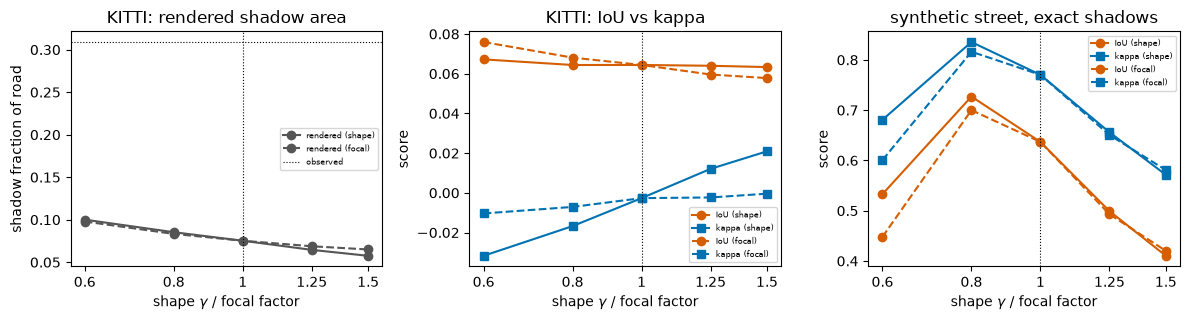

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for corr, ls in [("shape", "-"), ("focal", "--")]:
    m = k[k.corruption == corr].groupby("value").mean(numeric_only=True)
    axes[0].plot(m.index, m.rendered_frac, "o" + ls, color="#555555", label=f"rendered ({corr})")
    axes[1].plot(m.index, m.iou, "o" + ls, color="#D55E00", label=f"IoU ({corr})")
    axes[1].plot(m.index, m.kappa, "s" + ls, color="#0072B2", label=f"kappa ({corr})")
    s = syn[syn.corruption == corr].groupby("value").mean(numeric_only=True)
    axes[2].plot(s.index, s.iou, "o" + ls, color="#D55E00", label=f"IoU ({corr})")
    axes[2].plot(s.index, s.kappa, "s" + ls, color="#0072B2", label=f"kappa ({corr})")
axes[0].axhline(k.obs_frac.mean(), color="k", lw=0.8, ls=":", label="observed")
axes[0].set(ylabel="shadow fraction of road", title="KITTI: rendered shadow area")
axes[1].set(ylabel="score", title="KITTI: IoU vs kappa")
axes[2].set(ylabel="score", title="synthetic street, exact shadows")
for ax in axes:
    ax.axvline(1.0, color="k", lw=0.8, ls=":")
    ax.set_xscale("log")
    ax.set_xticks(VALUES, [f"{v:g}" for v in VALUES])
    ax.minorticks_off()
    ax.set_xlabel(r"shape $\gamma$ / focal factor")
    ax.legend(fontsize=6)
fig.tight_layout()
plt.savefig(FIG / "06_coverage_bias.png", dpi=90)

## 3. Is the KITTI IoU above chance at all?
Two independent masks with coverages r and o on the same region reach an expected IoU of
r*o / (r + o - r*o). We compare it with the measured IoU at the true depth.

In [6]:
t = k[k.value == 1.0].drop_duplicates("frame")
r, o = t.rendered_frac, t.obs_frac
t = t.assign(chance_iou=r * o / (r + o - r * o))
excess = t.iou - t.chance_iou
chance = dict(iou=t.iou.mean(), chance_iou=t.chance_iou.mean(), excess=excess.mean(),
              excess_lo=boot_frames(excess)[0], excess_hi=boot_frames(excess)[1], kappa=t.kappa.mean())
pd.Series(chance).round(4).to_csv(OUT / "coverage_bias_chance.csv", header=["value"])
pd.Series(chance).round(4)

iou           0.0644
chance_iou    0.0625
excess        0.0019
excess_lo    -0.0224
excess_hi     0.0341
kappa        -0.0027
dtype: float64

## 4. A focal error is a sun error
With focal k*f the depth map reconstructs D X, D = diag(1/k, 1/k, 1), and its shadows under the
sun s are exactly the true scene's shadows under D^-1 s = (k s_x, k s_y, s_z)
(`tests/test_geometry.py::test_focal_error_is_a_sun_error`). Locally a shape warp acts the same
way with D^-1 s = (s_x, s_y, s_z / gamma). So each depth error equals a sun-direction error of
some angle, and a score that cannot locate the sun to that angle cannot see the depth error.

In [7]:
def angle(a, b):
    return float(np.degrees(np.arccos(np.clip(a @ b / np.linalg.norm(a) / np.linalg.norm(b), -1, 1))))


suns = [sun.sun_in_camera(oxts, i, stamps[i], calib, UTC_OFFSET)[0] for i in sorted(k.frame.unique())]
eq = []
for v in VALUES:
    if v == 1.0:
        continue
    for corr, scale in [("focal", np.array([v, v, 1.0])), ("shape", np.array([1.0, 1.0, 1 / v]))]:
        eq.append(dict(corruption=corr, value=v, sun_angle_deg=np.mean([angle(s, s * scale) for s in suns])))
eq = pd.DataFrame(eq).pivot(index="value", columns="corruption", values="sun_angle_deg")
eq.round(1).to_csv(OUT / "equivalent_sun_error.csv")
eq.round(1)

corruption,focal,shape
value,,
0.60,8.9,8.9
0.80,3.5,3.5
1.25,2.9,2.9
1.50,4.8,4.8


## Reading

- **Compressed depth casts more shadow.** On drive 0001 the rendered shadow covers 7.5 % of
  the road at the true depth and 10 % at gamma 0.6 or focal 0.6 (1.3x the area).
- **The IoU follows the area, not the geometry.** Within a frame the IoU correlates with the
  rendered area (r = 0.48), so a wrong depth that casts more shadow scores better.
- **At the true depth the IoU is at chance.** Measured IoU 0.064 against 0.063 for two
  independent masks of the same coverage (excess 0.002, 95 % frame bootstrap -0.022 to
  0.034), and kappa is -0.003. On real KITTI frames the
  rendered shadows carry no information about the observed ones beyond their area.
- **A chance-corrected score does not rescue it.** Kappa removes the pull towards large masks
  but, with no signal left, it now prefers the *smaller* masks of expanded depth (r = -0.51
  with area); the truth is never the per-frame argmax.
- **On the synthetic street kappa keeps the signal**: 0.77 at the truth, 0.57-0.60 at +-50 %.
  Both scores peak at 0.8 rather than 1.0: the screen-space renderer misses about 15 % of
  the exact shadow, and the longer shadows of compressed depth make up part of it (notebook 04).

- **A focal or shape error is a small sun error.** (k s_x, k s_y, s_z) and (s_x, s_y, s_z / k) point
  the same way, so a focal factor k and a local warp gamma = k look the same to a shadow, which is
  why their curves match. On drive 0001 a 40 % error (0.6) equals an 8.9 deg sun error and a 20 %
  error (0.8) 3.5 deg. Per frame the pipeline does not even locate the sun to 30 deg (notebook 05).

So the failure on KITTI is not a scoring artefact that a better metric fixes: the rendered
and observed shadows do not agree beyond chance. Fixing it needs better shadows on both sides
(visible casters, a renderer without the thickness assumption), not a better score.